# Online Retail | Análise exploratória de vendas com Python
**Rafael Gonçalves · Projeto orientado Coursera**

Uma loja online do Reino Unido precisa decidir quando reforçar a operação, quais produtos priorizar e quais clientes acompanhar. A unidade de observação é a **linha de fatura**. Um pedido pode conter várias linhas.

O notebook usa o arquivo original `Online Retail.xlsx`, fornecido com o projeto. Para reproduzir, mantenha a planilha ao lado do notebook, instale `pandas`, `numpy`, `openpyxl` e `matplotlib` e execute as células em ordem. Valores monetários em libras esterlinas (GBP). Fonte pública e dicionário de dados no [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail).

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

arquivo = Path("Online Retail.xlsx")
base = pd.read_excel(arquivo, dtype={"InvoiceNo":"string", "StockCode":"string", "CustomerID":"Int64"})
colunas = {"InvoiceNo","StockCode","Description","Quantity","InvoiceDate","UnitPrice","CustomerID","Country"}
assert colunas.issubset(base.columns)
print("Linhas e colunas:", base.shape)
print("Período observado:", base.InvoiceDate.min(), "a", base.InvoiceDate.max())
print("SHA-256:", hashlib.sha256(arquivo.read_bytes()).hexdigest())
print(base.head().to_string(index=False))
perfil = pd.DataFrame({"Tipo":base.dtypes, "Ausências":base.isna().sum(),
                       "% ausente":100*base.isna().mean()})
print(perfil.round(2).to_string())

Linhas e colunas: (541909, 8)
Período observado: 2010-12-01 08:26:00 a 2011-12-09 12:50:00
SHA-256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d
InvoiceNo StockCode                         Description  Quantity         InvoiceDate  UnitPrice  CustomerID        Country
   536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6 2010-12-01 08:26:00       2.55       17850 United Kingdom
   536365     71053                 WHITE METAL LANTERN         6 2010-12-01 08:26:00       3.39       17850 United Kingdom
   536365    84406B      CREAM CUPID HEARTS COAT HANGER         8 2010-12-01 08:26:00       2.75       17850 United Kingdom
   536365    84029G KNITTED UNION FLAG HOT WATER BOTTLE         6 2010-12-01 08:26:00       3.39       17850 United Kingdom
   536365    84029E      RED WOOLLY HOTTIE WHITE HEART.         6 2010-12-01 08:26:00       3.39       17850 United Kingdom
                       Tipo  Ausências  % ausente
InvoiceNo    string[python]          0   

## 1. Qualidade e definição das métricas
Vendas brutas são linhas com quantidade e preço positivos em faturas sem prefixo C. Cancelamentos de valor têm prefixo C, quantidade negativa e preço positivo. Os demais registros ficam em ajustes ou exceções. O saldo observado corresponde a vendas brutas menos cancelamentos de valor, por data de registro, sem presumir vínculo com a compra original. Ele é uma medida analítica e exclui ajustes.

Sem chave única para a linha, registros idênticos podem representar repetição legítima. A análise principal retém todas as linhas e mede o efeito de deduplicá-las. Rankings de mercadorias usam a regra explícita de código com cinco dígitos seguidos opcionalmente de letras. O resumo de vendas inclui cobranças positivas elegíveis. Códigos fora do padrão aparecem na auditoria para revisão.

In [2]:
def classificar(dados):
    fatura_c = dados.InvoiceNo.str.strip().str.upper().str.startswith("C", na=False)
    valido = dados.InvoiceNo.notna() & dados.InvoiceDate.notna()
    vendas = valido & ~fatura_c & dados.Quantity.gt(0) & dados.UnitPrice.gt(0)
    cancela = valido & fatura_c & dados.Quantity.lt(0) & dados.UnitPrice.gt(0)
    return dados.assign(
        Valor=dados.Quantity.mul(dados.UnitPrice).round(2),
        Tipo=np.select([vendas.to_numpy(dtype=bool), cancela.to_numpy(dtype=bool)],
                       ["Venda", "Cancelamento"], default="Ajuste/exceção"),
    )

dados = classificar(base)
vendas = dados.loc[dados.Tipo.eq("Venda")].copy()
cancelamentos = dados.loc[dados.Tipo.eq("Cancelamento")].copy()
vendas["Mercadoria"] = vendas.StockCode.str.strip().str.fullmatch(r"[0-9]{5}[A-Za-z]*", na=False)
produtos = vendas.loc[vendas.Mercadoria].copy()
bruto = vendas.Valor.sum()
cancelado = -cancelamentos.Valor.sum()
saldo = bruto - cancelado
dedup = classificar(base.drop_duplicates())
assert dados.groupby("Tipo").size().sum() == len(base)
assert np.isclose(dados.groupby("Tipo").Valor.sum().sum(), dados.Valor.sum())
print(dados.groupby("Tipo").Valor.agg(Linhas="size", Valor_GBP="sum").round(2).to_string())
print(f"Vendas brutas: £{bruto:,.2f} | Cancelamentos: £{cancelado:,.2f} | Saldo: £{saldo:,.2f}")
print(f"Linhas idênticas adicionais: {base.duplicated().sum():,}")
variacao = dedup.loc[dedup.Tipo.eq("Venda"), "Valor"].sum()/bruto - 1
print(f"Efeito da deduplicação sobre o bruto: {variacao:.2%}")
print("Maiores códigos fora do padrão de mercadoria por valor bruto:")
print(vendas.loc[~vendas.Mercadoria].groupby("StockCode").Valor.sum().nlargest(10).round(2).to_string())

                Linhas    Valor_GBP
Tipo                               
Ajuste/exceção    2517    -22124.12
Cancelamento      9288   -896812.49
Venda           530104  10666684.54
Vendas brutas: £10,666,684.54 | Cancelamentos: £896,812.49 | Saldo: £9,769,872.05
Linhas idênticas adicionais: 5,268
Efeito da deduplicação sobre o bruto: -0.23%
Maiores códigos fora do padrão de mercadoria por valor bruto:
StockCode
DOT             206248.77
M                78110.27
POST             78101.88
AMAZONFEE        13761.09
B                11062.06
C2                7051.00
gift_0001_30       175.53
gift_0001_50       167.56
gift_0001_20       167.05
BANK CHARGES       165.00


## 2. Distribuição, anomalias e correlação
O ticket de venda é o valor bruto agregado por fatura. A regra de Tukey (Q3 + 1,5 × IQR) sinaliza pedidos para revisão. A visualização usa escala logarítmica para mostrar a cauda e o cálculo preserva os pedidos extremos. As correlações entre preço e quantidade são descritivas. Elas misturam produtos, clientes e períodos, portanto não estimam elasticidade.

        Quantity  UnitPrice      Valor
count  530104.00  530104.00  530104.00
mean       10.54       3.91      20.12
std       155.52      35.92     270.36
min         1.00       0.00       0.00
50%         3.00       2.08       9.90
95%        30.00       9.95      59.70
99%       100.00      16.98     183.60
max     80995.00   13541.33  168469.60
Pedidos: 19,960 | Média: £534.40 | Mediana: £303.83
Limite de Tukey: £1,010.27 | Pedidos acima: 1,811 | Participação no bruto: 47.7%
Participação das cinco maiores faturas: 3.64%
InvoiceNo
581483    168469.60
541431     77183.60
574941     52940.94
576365     50653.91
556444     38970.00
           Quantity  UnitPrice
Quantity      1.000     -0.022
UnitPrice    -0.022      1.000
Spearman (postos): -0.401


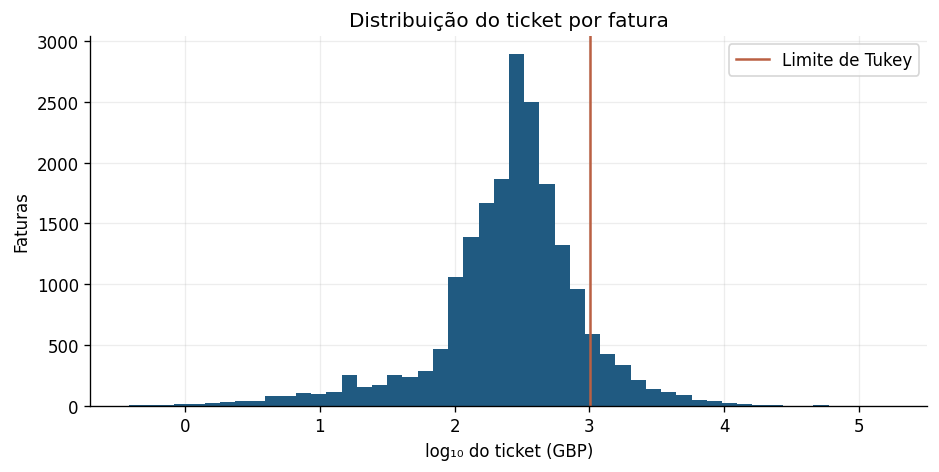

In [3]:
plt.rcParams.update({"figure.figsize":(9,4), "axes.spines.top":False, "axes.spines.right":False,
                     "axes.grid":True, "axes.axisbelow":True, "grid.alpha":0.22})
azul, verde, terra = "#205A81", "#25837C", "#BA6043"
pedidos = vendas.groupby("InvoiceNo").Valor.sum()
print(vendas[["Quantity","UnitPrice","Valor"]].describe(percentiles=[.5,.95,.99]).round(2).to_string())
print(f"Pedidos: {len(pedidos):,} | Média: £{pedidos.mean():,.2f} | Mediana: £{pedidos.median():,.2f}")
q1,q3 = pedidos.quantile([.25,.75])
limite = q3+1.5*(q3-q1)
extremos = pedidos[pedidos.gt(limite)]
maiores = pedidos.nlargest(5)
print(f"Limite de Tukey: £{limite:,.2f} | Pedidos acima: {len(extremos):,} | Participação no bruto: {extremos.sum()/bruto:.1%}")
print(f"Participação das cinco maiores faturas: {maiores.sum()/bruto:.2%}")
print(maiores.round(2).to_string())
print(produtos[["Quantity","UnitPrice"]].corr().round(3).to_string())
print("Spearman (postos):", round(produtos.Quantity.rank().corr(produtos.UnitPrice.rank()),3))
fig, ax = plt.subplots()
ax.hist(np.log10(pedidos), bins=50, color=azul)
ax.axvline(np.log10(limite), color=terra, label="Limite de Tukey")
ax.set(title="Distribuição do ticket por fatura", xlabel="log₁₀ do ticket (GBP)", ylabel="Faturas")
ax.legend()
plt.show()

## 3. Quando a operação precisa de capacidade?
O primeiro e o último mês foram avaliados pela cobertura de calendário. Dezembro de 2011 é parcial. Os dias da semana são comparados pelo volume total e pela média por dia com vendas, pois a frequência de operação varia. A média é condicional aos dias com vendas registradas.

                  Bruto  Cancelado       Saldo  Parcial
InvoiceDate                                            
2010-12       823746.14   74789.12   748957.02    False
2011-01       691364.56  131364.30   560000.26    False
2011-02       523631.89   25569.24   498062.65    False
2011-03       717639.36   34372.28   683267.08    False
2011-04       537808.62   44601.50   493207.12    False
2011-05       770536.02   47202.51   723333.51    False
2011-06       761739.90   70616.78   691123.12    False
2011-07       719221.19   37921.08   681300.11    False
2011-08       759138.38   54333.75   704804.63    False
2011-09      1058590.17   38902.55  1019687.62    False
2011-10      1154979.30   84274.63  1070704.67    False
2011-11      1509496.33   47740.08  1461756.25    False
2011-12       638792.68  205124.67   433668.01     True
             Dias       Total     Media
InvoiceDate                            
Seg            47  1779575.04  37863.30
Ter            52  2178632.61  41896.78


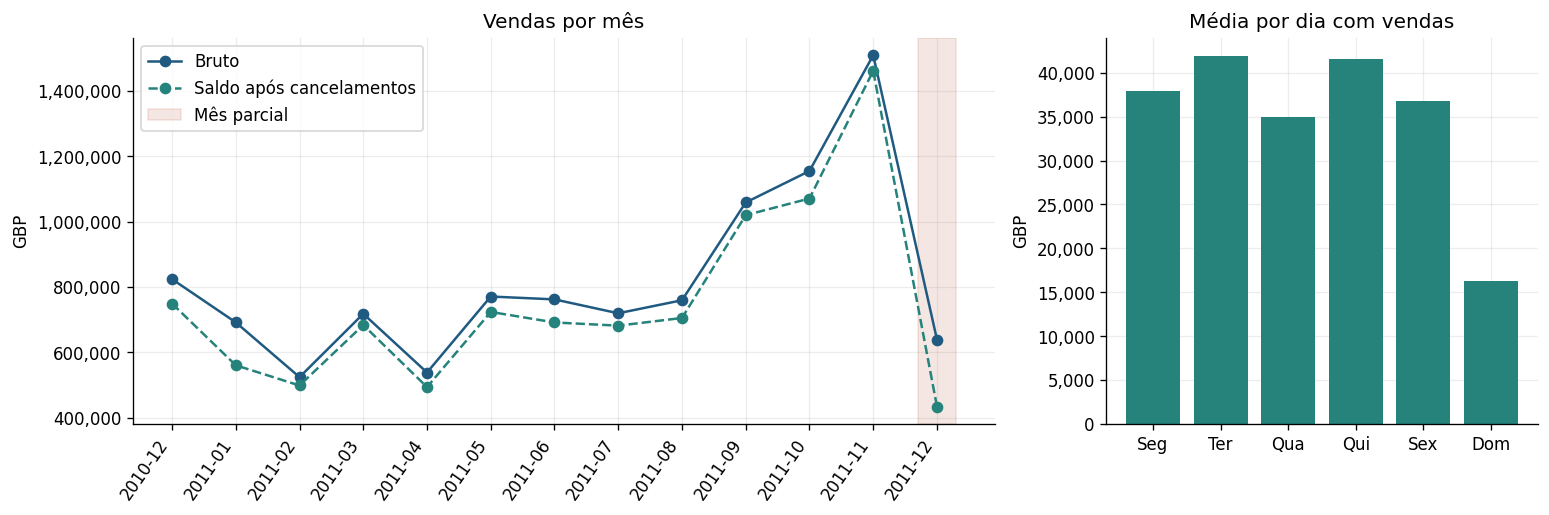

In [4]:
def serie_mensal(linhas):
    return linhas.groupby(linhas.InvoiceDate.dt.to_period("M")).Valor.sum()

mensal = pd.concat({"Bruto":serie_mensal(vendas), "Cancelado":-serie_mensal(cancelamentos)}, axis=1).fillna(0)
mensal["Saldo"] = mensal.Bruto - mensal.Cancelado
inicio, fim = dados.InvoiceDate.min(), dados.InvoiceDate.max()
mensal["Parcial"] = [(p.start_time.date() < inicio.date()) or
                    (p.end_time.date() > fim.date()) for p in mensal.index]
print(mensal.round(2).to_string())
pico = mensal.loc[~mensal.Parcial, "Bruto"].idxmax()
diario = vendas.groupby(vendas.InvoiceDate.dt.normalize()).Valor.sum()
semana = diario.groupby(diario.index.dayofweek).agg(Dias="size", Total="sum", Media="mean")
semana.index = semana.index.map(dict(enumerate(["Seg","Ter","Qua","Qui","Sex","Sáb","Dom"])))
print(semana.round(2).to_string())
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13,4.4), gridspec_kw={"width_ratios":[2,1]})
x = np.arange(len(mensal))
ax.plot(x, mensal.Bruto, "o-", color=azul, label="Bruto")
ax.plot(x, mensal.Saldo, "o--", color=verde, label="Saldo após cancelamentos")
for pos in x[mensal.Parcial.to_numpy()]:
    ax.axvspan(pos-.3, pos+.3, color=terra, alpha=.15, label="Mês parcial" if pos == x[mensal.Parcial.to_numpy()][0] else None)
ax.set_xticks(x, mensal.index.astype(str), rotation=55, ha="right")
ax.set(title="Vendas por mês", ylabel="GBP")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend()
ax2.bar(semana.index, semana.Media, color=verde)
ax2.set(title="Média por dia com vendas", ylabel="GBP")
ax2.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
plt.show()

## 4. Produtos e mercados
A quantidade mede demanda em unidades registradas, que podem ter tamanhos de embalagem distintos. O valor bruto mede contribuição às vendas. A análise agrupa produtos pelo código, usando a descrição mais frequente como rótulo. Os países são comparados por unidades de mercadoria e valor bruto de todas as linhas elegíveis.

           Unidades      Bruto                         Description
StockCode                                                         
23843         80995  168469.60         PAPER CRAFT , LITTLE BIRDIE
23166         78033   81700.92      MEDIUM CERAMIC TOP STORAGE JAR
22197         56921   51354.02                      POPCORN HOLDER
84077         55047   13841.85   WORLD WAR 2 GLIDERS ASSTD DESIGNS
85099B        48474   94340.05             JUMBO BAG RED RETROSPOT
85123A        37660  104518.80  WHITE HANGING HEART T-LIGHT HOLDER
84879         36461   59094.93       ASSORTED COLOUR BIRD ORNAMENT
21212         36419   21259.10     PACK OF 72 RETROSPOT CAKE CASES
           Unidades      Bruto                         Description
StockCode                                                         
22423         13879  174484.74            REGENCY CAKESTAND 3 TIER
23843         80995  168469.60         PAPER CRAFT , LITTLE BIRDIE
85123A        37660  104518.80  WHITE HANGING HEART T-LIGHT HO

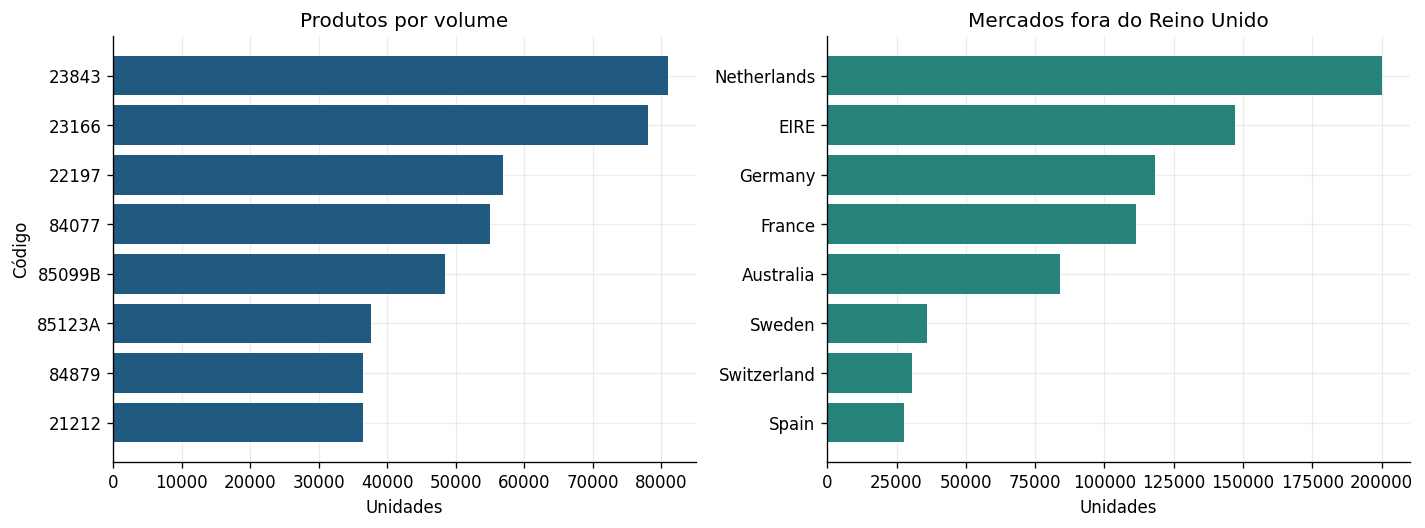

In [5]:
rotulos = (produtos.dropna(subset=["Description"]).groupby(["StockCode","Description"])
           .size().rename("Frequencia").reset_index()
           .sort_values(["Frequencia","Description"], ascending=[False,True])
           .drop_duplicates("StockCode").set_index("StockCode").Description)
ranking = produtos.groupby("StockCode").agg(Unidades=("Quantity","sum"), Bruto=("Valor","sum")).join(rotulos)
paises = vendas.groupby("Country").agg(Bruto=("Valor","sum"), Pedidos=("InvoiceNo","nunique"))
paises["Unidades"] = produtos.groupby("Country").Quantity.sum()
top_unidades = ranking.nlargest(8,"Unidades")
top_valor = ranking.nlargest(8,"Bruto")
print(top_unidades.round(2).to_string())
print(top_valor.round(2).to_string())
print(paises.nlargest(10,"Unidades").round(2).to_string())
fig, (ax, ax2) = plt.subplots(1,2,figsize=(12,4.5))
ax.barh(top_unidades.index[::-1],top_unidades.Unidades[::-1],color=azul)
ax.set(title="Produtos por volume",xlabel="Unidades",ylabel="Código")
top_exterior = paises.drop(index="United Kingdom").nlargest(8,"Unidades").sort_values("Unidades")
ax2.barh(top_exterior.index,top_exterior.Unidades,color=verde)
ax2.set(title="Mercados fora do Reino Unido",xlabel="Unidades")
fig.tight_layout()
plt.show()

## 5. Clientes, recorrência e RFM
Recência conta dias desde a última compra até o dia seguinte ao fim da amostra. Frequência conta faturas de venda distintas. Valor monetário soma vendas brutas por cliente identificado. A tabela preserva empates em frequência e informa os limites dos quartis em vez de forçar quatro grupos com o mesmo tamanho.

In [6]:
identificadas = vendas.dropna(subset=["CustomerID"])
referencia = fim.normalize()+pd.Timedelta(days=1)
rfm = identificadas.groupby("CustomerID").agg(
    Ultima=("InvoiceDate","max"), Frequencia=("InvoiceNo","nunique"), Monetario=("Valor","sum"))
rfm["Recencia_dias"] = (referencia-rfm.Ultima.dt.normalize()).dt.days
col_rfm = ["Recencia_dias","Frequencia","Monetario"]
print(rfm[col_rfm].describe().round(2).to_string())
print(f"Clientes identificados: {len(rfm):,} | Clientes com ≥2 pedidos: {rfm.Frequencia.ge(2).mean():.1%}")
print(f"Valor bruto sem CustomerID: {1-identificadas.Valor.sum()/bruto:.1%}")
lideres = rfm.nlargest(10,"Monetario")
print(lideres[col_rfm].round(2).to_string())
ativos = rfm.Recencia_dias.le(rfm.Recencia_dias.quantile(.25))
frequentes = rfm.Frequencia.ge(rfm.Frequencia.quantile(.75))
alto_valor = rfm.Monetario.ge(rfm.Monetario.quantile(.75))
inativos = rfm.Recencia_dias.ge(rfm.Recencia_dias.quantile(.75))
print(f"Alta prioridade de retenção (R, F e M): {(ativos & frequentes & alto_valor).sum()}")
print(f"Alto valor histórico e recência no quartil mais antigo: {(inativos & alto_valor).sum()}")
print(f"Participação dos 10 líderes no bruto identificado: {lideres.Monetario.sum()/identificadas.Valor.sum():.1%}")

       Recencia_dias  Frequencia  Monetario
count        4338.00     4338.00    4338.00
mean           93.06        4.27    2054.27
std           100.01        7.70    8989.23
min             1.00        1.00       3.75
25%            18.00        1.00     307.41
50%            51.00        2.00     674.48
75%           142.75        5.00    1661.74
max           374.00      209.00  280206.02
Clientes identificados: 4,338 | Clientes com ≥2 pedidos: 65.6%
Valor bruto sem CustomerID: 16.5%
            Recencia_dias  Frequencia  Monetario
CustomerID                                      
14646                   2          73  280206.02
18102                   1          60  259657.30
17450                   9          46  194550.79
16446                   1           2  168472.50
14911                   2         201  143825.06
12415                  25          21  124914.53
14156                  10          55  117379.63
17511                   3          31   91062.38
16029            

## 6. Sensibilidade e exceções
Uma venda excepcional seguida por um cancelamento no mesmo dia pode inflar o bruto. A tabela procura sinais compatíveis em cliente, código, quantidade absoluta, preço e dia. Trata-se de uma triagem, pois a chave de fatura original não está presente nos cancelamentos.

In [7]:
chaves = ["CustomerID","StockCode","Quantity","UnitPrice","Dia"]
amostra = vendas.nlargest(10,"Valor").dropna(subset=["CustomerID"]).assign(
    Dia=lambda t:t.InvoiceDate.dt.normalize())
estornos = cancelamentos.dropna(subset=["CustomerID"]).assign(
    Quantity=lambda t:-t.Quantity, Dia=lambda t:t.InvoiceDate.dt.normalize())
sinais = estornos.groupby(chaves).InvoiceNo.nunique().rename("Faturas_C_compativeis")
triagem = amostra.join(sinais,on=chaves)
print(triagem[["InvoiceNo","StockCode","Quantity","Valor","Faturas_C_compativeis"]].fillna(0).to_string(index=False))
vendas_sem_top5 = vendas.loc[~vendas.InvoiceNo.isin(maiores.index)]
pico_robusto = serie_mensal(vendas_sem_top5).reindex(mensal.index).loc[~mensal.Parcial].idxmax()
print("Pico mensal sem as cinco maiores faturas:", pico_robusto)
produtos_sem_top5 = produtos.loc[~produtos.InvoiceNo.isin(maiores.index)]
volume_robusto = produtos_sem_top5.groupby("StockCode").Quantity.sum().nlargest(5)
print("Líderes em unidades sem as cinco maiores faturas:")
print(volume_robusto.to_string())
saldo_pico = mensal.loc[~mensal.Parcial,"Saldo"].idxmax()
print("Pico mensal por saldo após cancelamentos:", saldo_pico)

InvoiceNo StockCode  Quantity     Valor  Faturas_C_compativeis
   581483     23843     80995 168469.60                    1.0
   541431     23166     74215  77183.60                    1.0
   556444     22502        60  38970.00                    0.0
   551697      POST         1   8142.75                    1.0
   567423     23243      1412   7144.72                    0.0
   540815     21108      3114   6539.40                    0.0
   550461     21108      3114   6539.40                    1.0
   573003     23084      2400   4992.00                    0.0
Pico mensal sem as cinco maiores faturas: 2011-11
Líderes em unidades sem as cinco maiores faturas:
StockCode
84077     55047
22197     53971
85099B    48474
85123A    37660
84879     36461
Pico mensal por saldo após cancelamentos: 2011-11


## 7. Conclusões e decisões

- **Capacidade.** 2011-11 liderou os meses completos, com **£1.509.496,33** em vendas brutas. O mês líder após excluir as cinco maiores faturas foi **2011-11** e pelo saldo após cancelamentos foi **2011-11**. **Qui** liderou no total acumulado por dia da semana e **Ter** em média por dia com vendas. Use esses padrões como ponto de partida para dimensionar estoque e expedição. A base cobre apenas um ciclo anual e dezembro de 2011 é parcial.
- **Sortimento.** **PAPER CRAFT , LITTLE BIRDIE (23843)** liderou em unidades. **REGENCY CAKESTAND 3 TIER (22423)** liderou em valor bruto. O SKU 23843 teve toda a quantidade bruta registrada em uma fatura com indício de estorno. Sem as cinco maiores faturas, o líder em volume é **WORLD WAR 2 GLIDERS ASSTD DESIGNS (84077)**. Valide cancelamentos antes de usar o ranking para reposição e combine valor com margem para decidir exposição. A base não informa custos.
- **Mercados.** O Reino Unido respondeu por **84.6%** do bruto. **Netherlands** liderou em unidades entre os demais países. Antes de investir em expansão, compare custo de entrega e cancelamentos por destino.
- **Retenção.** **4,338** clientes fizeram compras identificadas e **65.6%** voltaram a comprar dentro da janela. Use os segmentos RFM para testar contatos de retenção e reativação. Meça o efeito incremental com um grupo de controle. **16.5%** do bruto ficou sem identificação e a janela de observação limita a leitura de recorrência.
- **Qualidade.** A triagem encontrou **4** linhas, entre as maiores vendas identificadas revisadas, com sinais compatíveis de cancelamento no mesmo dia. Revise os documentos de origem para distinguir grandes pedidos de registros revertidos. O saldo analítico não equivale à receita contábil, e as correlações observadas não estabelecem causalidade.

- **Distribuição.** O ticket médio foi **£534,40**, frente à mediana de **£303,83**. A diferença reflete uma cauda de pedidos grandes. A associação entre quantidade e preço unitário foi mais visível nos postos (Spearman −0,401) do que em escala linear (Pearson −0,022), compatível com diferenças de mix entre produtos e tamanhos de pedido.

### Resumo para o portfólio
Analisei transações de uma loja online do Reino Unido com Python e pandas. Auditei registros ausentes, duplicados e cancelamentos, comparei vendas por período, produto e país e segmentei clientes por recência, frequência e valor. Testei a robustez do pico de vendas à exclusão de pedidos extremos e converti os resultados em propostas para estoque, expedição e retenção.